# Stories Café: Lebanon's Price Changes vs the Café's Prices and Costs

**Questions**
1. How did prices change in Lebanon from January to June 2026?
2. Did the café's selling prices or ingredient costs change in the data over the same period?
3. If they didn't, what does that mean for real (inflation-adjusted) prices, margins and the profit planner?

**External data:** Lebanon's consumer price index (CPI) from the Central Administration of Statistics (CAS), as reported by Credit Libanais, BLOMINVEST and Trading Economics, plus reported input-cost changes (flour, bread, fuel). Everything is stored with its source links and retrieval date (2026-10-17) in `data/external/lebanon_cpi_2026H1.json`. Some monthly index levels are **derived** from published monthly changes; the file marks which.

**Ground rules (from AGENTS.md):** all transaction rows are kept, including the 132 repeated lines. We don't estimate price sensitivity, and we don't claim inflation caused any change in sales. CPI is national, and branch locations aren't confirmed, so nothing here is branch-specific exposure.

**Sections**
1. Setup
2. What happened to prices in Lebanon
3. Did the café's selling prices change?
4. Did the café's ingredient costs change?
5. Real (inflation-adjusted) prices and revenue
6. What if costs actually rose with inflation? Margin scenarios
7. Conclusion and what it means for the planner

## 1. Setup

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
CPI_COLOR, CAFE_COLOR, WAR_SHADE = "#e34948", "#2a78d6", "#f3d9d3"
ACCENT, MUTED = "#2a78d6", "#b9b8b3"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
SEQ_SCEN = ["#9ec5f4", "#3987e5", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
R, GP = "Line Revenue (USD)", "Line Gross Profit (USD)"

cpi_raw = json.loads(open("../data/external/lebanon_cpi_2026H1.json", encoding="utf-8").read())
cpi = pd.DataFrame(cpi_raw["monthly"]).set_index("month")
cpi.index = pd.PeriodIndex(cpi.index, freq="M")

df = pd.read_csv("../data/stories_transactions.csv")  # all rows kept, as agreed in AGENTS.md
df["Date"] = pd.to_datetime(df["Date"])
df["month"] = df["Date"].dt.to_period("M")
df["list_value"] = df["Quantity"] * df["Unit Price (USD)"]
df["cost_value"] = df["Quantity"] * df["Unit Cost (USD)"]
print(f"{len(df):,} transaction lines, {df['Date'].min():%b %d} to {df['Date'].max():%b %d, %Y}")
cpi[["cpi_index", "index_status", "mom_pct", "yoy_pct"]]

51,177 transaction lines, Jan 01 to Jun 30, 2026


,cpi_index,index_status,mom_pct,yoy_pct
month,,,,
2026-01,7917.70,derived: Feb index / 1.0190,-0.08,NaN
2026-02,8068.09,published,1.90,12.27
2026-03,8464.20,derived: Feb index x 1.0491,4.91,17.30
2026-04,8721.39,published,3.04,20.02
2026-05,8763.25,derived: Apr index x 1.0048,0.48,19.04
2026-06,8697.50,derived: May index x 0.9925,-0.75,17.25


## 2. What happened to prices in Lebanon

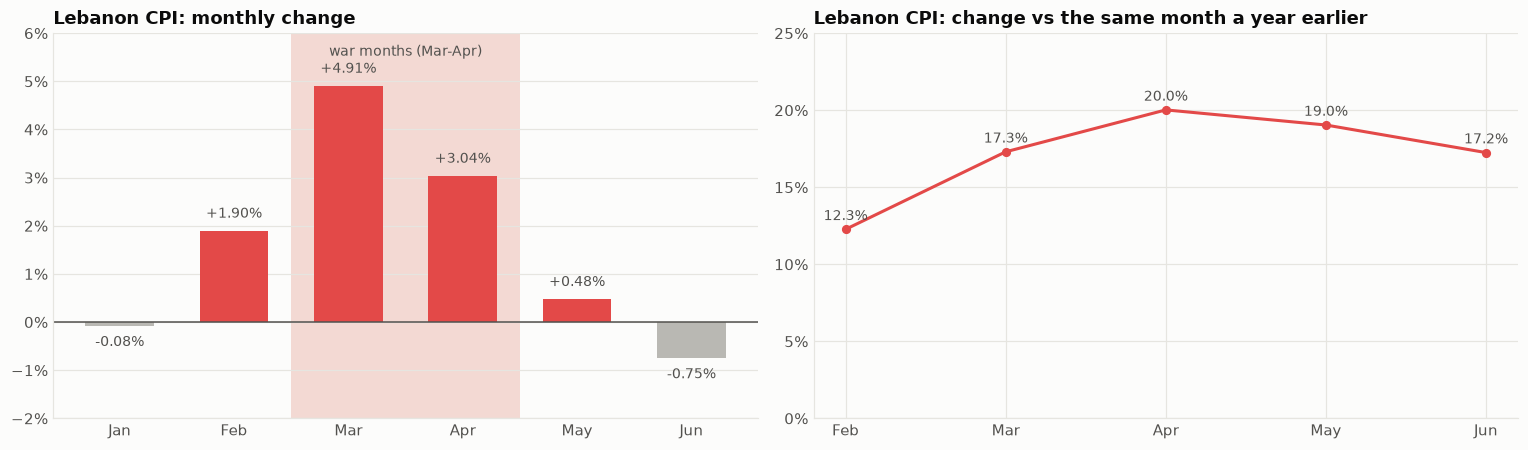

CPI change from January to June: +9.8% (Feb to Jun: +7.8%)


,Feb,Mar,Apr,May,Jun
food_and_non_alcoholic_beverages,+16.0%,+19.4%,+18.0%,not reported,not reported
housing_and_utilities,not reported,+20.3%,not reported,not reported,not reported
restaurants_and_hotels,+7.9%,+11.3%,+16.0%,not reported,not reported
transportation,+6.0%,+24.8%,+33.3%,+37.8%,+29.4%
water_electricity_gas_other_fuels,+6.2%,not reported,+41.4%,not reported,not reported


In [2]:
months = [p.strftime("%b") for p in cpi.index]
cum = cpi["cpi_index"] / cpi["cpi_index"].iloc[0] - 1  # change since January

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
colors = [CPI_COLOR if v > 0 else MUTED for v in cpi["mom_pct"]]
ax.bar(months, cpi["mom_pct"] / 100, color=colors, width=0.6)
for i, v in enumerate(cpi["mom_pct"]):
    ax.text(i, v / 100 + (0.002 if v >= 0 else -0.002), f"{v:+.2f}%", ha="center", va="bottom" if v >= 0 else "top",
            color=INK2, fontsize=9)
ax.axhline(0, color=INK2, lw=1)
ax.axvspan(1.5, 3.5, color=WAR_SHADE, lw=0, zorder=0)
ax.text(2.5, 0.97, "war months (Mar-Apr)", transform=ax.get_xaxis_transform(), ha="center", va="top", color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(-0.02, 0.06)
ax.set_title("Lebanon CPI: monthly change")
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.plot(months, cpi["yoy_pct"] / 100, color=CPI_COLOR, marker="o", ms=5)
for i, v in enumerate(cpi["yoy_pct"]):
    if pd.notna(v):
        ax.text(i, v / 100 + 0.006, f"{v:.1f}%", ha="center", color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.25)
ax.set_title("Lebanon CPI: change vs the same month a year earlier")
plt.tight_layout()
plt.show()

comp = pd.DataFrame({m.strftime("%b"): pd.Series(cpi.loc[m, "components_yoy_pct"]) for m in cpi.index
                     if isinstance(cpi.loc[m, "components_yoy_pct"], dict)})
print(f"CPI change from January to June: {cum.iloc[-1]:+.1%} (Feb to Jun: {cpi['cpi_index'].iloc[-1] / cpi['cpi_index'].iloc[1] - 1:+.1%})")
comp.style.format("{:+.1f}%", na_rep="not reported").set_caption("Selected CPI components: % change vs a year earlier")

In [3]:
pd.DataFrame(cpi_raw["context"]["reported_input_costs"])[["item", "change", "type"]]

,item,change,type
0,flour (bakery bag),about $20 to $25-40 in March 2026,"anecdotal, one baker"
1,bread,"+5,000 LBP per bag set by the Ministry of Econ...",official price decision as reported in news
2,gasoline / diesel,about +80% / +85% (date range not specified),NGO report


**Takeaway**
- **Prices in Lebanon jumped when the war began.** The CPI rose **+4.91% in March** (the biggest monthly rise since October 2023) and **+3.04% in April**, then flattened (+0.48% in May, -0.75% in June). Over January to June, the CPI rose about **+9.8%**.
- **Year-on-year inflation went from 12% in February to 20% in April**, then eased to 17% in June.
- The parts that matter for a café rose too: **food +18-19%** and **restaurants and hotels from +8% (Feb) to +16% (Apr)** year-on-year. Transport and fuel-related costs rose fastest (+25-41%), driven by oil prices.
- Reports describe flour bags going from about $20 to $25-40 in March, a government-set bread price increase, and fuel up about 80%.
- The lira stayed near **89,500 per dollar** all period, so these increases are real increases in dollar terms too, not a currency effect.

## 3. Did the café's selling prices change?

Branch-product combinations: 135
Combinations with more than one selling price over six months: 0
Combinations with more than one unit cost over six months:     0


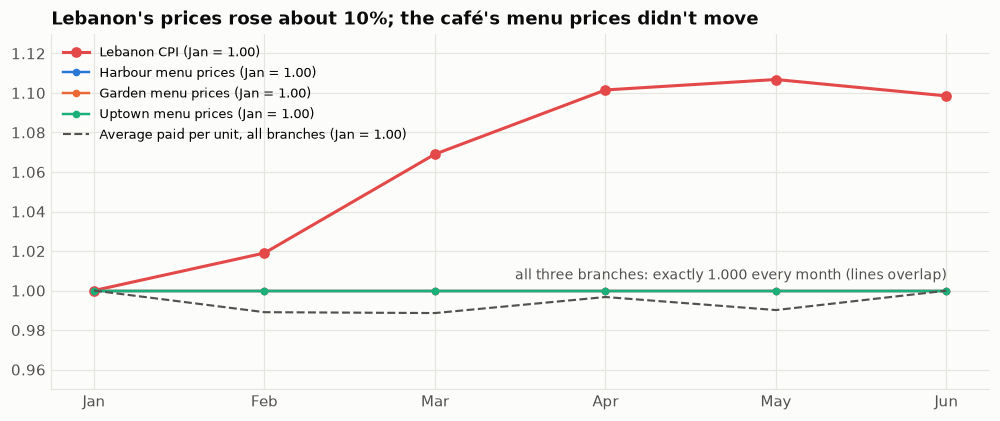

,Harbour,Garden,Uptown
Jan,1.000,1.000,1.000
Feb,1.000,1.000,1.000
Mar,1.000,1.000,1.000
Apr,1.000,1.000,1.000
May,1.000,1.000,1.000
Jun,1.000,1.000,1.000


In [4]:
variants = df.groupby(["Branch", "Product"]).agg(price_variants=("Unit Price (USD)", "nunique"),
                                                 cost_variants=("Unit Cost (USD)", "nunique"),
                                                 first_sold=("Date", "min"), last_sold=("Date", "max"))
print(f"Branch-product combinations: {len(variants)}")
print(f"Combinations with more than one selling price over six months: {(variants['price_variants'] > 1).sum()}")
print(f"Combinations with more than one unit cost over six months:     {(variants['cost_variants'] > 1).sum()}")

# Fixed-basket price index: January quantities valued at each month's list prices (a Laspeyres index), by branch
jan_qty = df[df["month"] == df["month"].min()].groupby(["Branch", "Product"])["Quantity"].sum()
price_by_month = df.groupby(["month", "Branch", "Product"])["Unit Price (USD)"].first()
basket = {}
for m in sorted(df["month"].unique()):
    p = price_by_month.loc[m]
    basket[m] = {b: (p.loc[b] * jan_qty.loc[b]).sum() / (price_by_month.loc[df["month"].min()].loc[b] * jan_qty.loc[b]).sum()
                 for b in BRANCHES}
cafe_index = pd.DataFrame(basket).T
cafe_index.index = [p.strftime("%b") for p in cafe_index.index]

# What customers actually paid per unit (after discounts), which also moves with the product mix
paid = df.groupby(["month"]).apply(lambda g: g[R].sum() / g["Quantity"].sum(), include_groups=False)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(months, (cpi["cpi_index"] / cpi["cpi_index"].iloc[0]).values, color=CPI_COLOR, marker="o", label="Lebanon CPI (Jan = 1.00)")
for b in BRANCHES:
    ax.plot(cafe_index.index, cafe_index[b].values, color=BRANCH_COLORS[b], marker="o", ms=4, lw=1.6,
            label=f"{b} menu prices (Jan = 1.00)")
ax.plot(months, (paid / paid.iloc[0]).values, color=INK2, ls="--", lw=1.4, label="Average paid per unit, all branches (Jan = 1.00)")
ax.text(len(months) - 1, 1.004, "all three branches: exactly 1.000 every month (lines overlap)", ha="right",
        va="bottom", color=INK2, fontsize=9)
ax.set_ylim(0.95, 1.13)
ax.set_title("Lebanon's prices rose about 10%; the café's menu prices didn't move")
ax.legend(loc="upper left", fontsize=8.5)
plt.show()
cafe_index.style.format("{:.3f}").set_caption("Fixed-basket menu price index by branch (January = 1.000)")

**Takeaway:** **not a single price changed.** Each of the 135 branch-product combinations has exactly one selling price for all six months, and the fixed-basket menu price index is exactly 1.000 in every month at every branch. The average amount paid per unit wobbles by about ±1% only because of the product mix and the random 10% discount (`07_discounts`), not because of price changes.

## 4. Did the café's ingredient costs change?

In [5]:
cost_month = df.groupby("month").agg(units=("Quantity", "sum"), cost=("cost_value", "sum"), revenue=(R, "sum"),
                                     list_value=("list_value", "sum"))
cost_month["cost_per_unit"] = cost_month["cost"] / cost_month["units"]
cost_month["cost_as_share_of_revenue"] = cost_month["cost"] / cost_month["revenue"]
cost_month["gross_margin"] = 1 - cost_month["cost_as_share_of_revenue"]
cost_month.index = [p.strftime("%b") for p in cost_month.index]

food_yoy = comp.loc["food_and_non_alcoholic_beverages"] if "food_and_non_alcoholic_beverages" in comp.index else None
cost_month[["cost_per_unit", "cost_as_share_of_revenue", "gross_margin"]].style.format(
    {"cost_per_unit": "${:.3f}", "cost_as_share_of_revenue": "{:.1%}", "gross_margin": "{:.1%}"}).set_caption(
    "Café cost per unit and margin by month (moves only with the product mix)")

,cost_per_unit,cost_as_share_of_revenue,gross_margin
Jan,$2.355,41.4%,58.6%
Feb,$2.330,41.4%,58.6%
Mar,$2.325,41.3%,58.7%
Apr,$2.347,41.4%,58.6%
May,$2.327,41.3%,58.7%
Jun,$2.349,41.3%,58.7%


**Takeaway:** ingredient costs in the data are **also completely fixed**: one unit cost per branch-product for all six months. Cost per unit and gross margin (58.6-58.7%) stay flat from January to June, even though food prices nationally were up 16-19% year-on-year, flour reportedly jumped 25-100% in March and fuel about 80%.

**What this most likely means** (we can't tell which from the data alone):
- the costs are **standard recipe costs** set once (for example at the start of the year), not the actual invoice prices paid each month; or
- the company **held its prices and absorbed** any real cost increases, and the cost field doesn't record them; or
- the company had **fixed supplier contracts** in dollars for the whole period.

Only the company can say which. It matters, because the profit planner and the pitch use these costs to calculate profit.

## 5. Real (inflation-adjusted) prices and revenue

If menu prices stay the same while everything else gets about 10% more expensive, the café's prices become about 10% cheaper **in real terms**. We divide the café's numbers by the CPI (January = 1) to see them in January money.

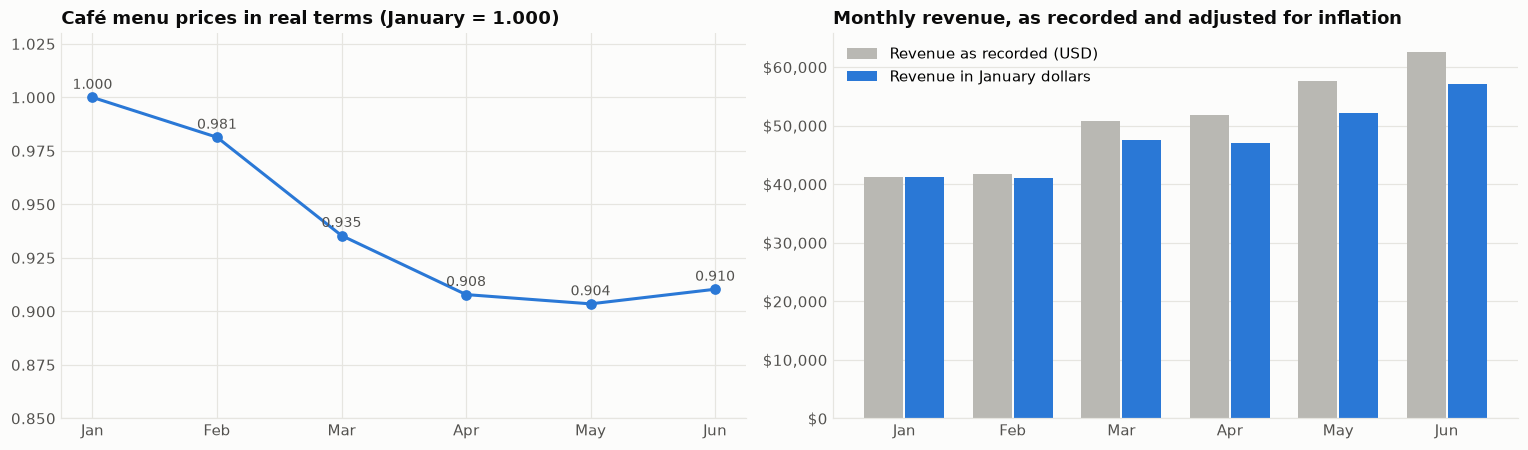

,Jan to Jun change
Revenue as recorded,+52.2%
Revenue in January dollars,+38.6%
Units sold,+52.3%
Real menu price,-9.0%


In [6]:
monthly = df.groupby("month").agg(revenue=(R, "sum"), profit=(GP, "sum"), units=("Quantity", "sum"))
monthly.index = [p.strftime("%b") for p in monthly.index]
deflator = (cpi["cpi_index"] / cpi["cpi_index"].iloc[0]).values
monthly["real_revenue_jan_usd"] = monthly["revenue"] / deflator
monthly["real_menu_price_index"] = 1 / deflator

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
ax.plot(monthly.index, monthly["real_menu_price_index"], color=CAFE_COLOR, marker="o")
for i, v in enumerate(monthly["real_menu_price_index"]):
    ax.text(i, v + 0.004, f"{v:.3f}", ha="center", color=INK2, fontsize=9)
ax.set_ylim(0.85, 1.03)
ax.set_title("Café menu prices in real terms (January = 1.000)")
ax = axes[1]
x = np.arange(len(monthly))
ax.bar(x - 0.19, monthly["revenue"], width=0.36, color=MUTED, label="Revenue as recorded (USD)")
ax.bar(x + 0.19, monthly["real_revenue_jan_usd"], width=0.36, color=CAFE_COLOR, label="Revenue in January dollars")
ax.set_xticks(x, monthly.index)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_title("Monthly revenue, as recorded and adjusted for inflation")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

growth = pd.DataFrame({
    "Jan to Jun change": [monthly["revenue"].iloc[-1] / monthly["revenue"].iloc[0] - 1,
                          monthly["real_revenue_jan_usd"].iloc[-1] / monthly["real_revenue_jan_usd"].iloc[0] - 1,
                          monthly["units"].iloc[-1] / monthly["units"].iloc[0] - 1,
                          monthly["real_menu_price_index"].iloc[-1] - 1]},
    index=["Revenue as recorded", "Revenue in January dollars", "Units sold", "Real menu price"])
growth.style.format("{:+.1%}")

**Takeaway:** by June, the café's menu was about **9% cheaper in real terms** than in January. Recorded revenue grew about 52% from January to June, about 39% after adjusting for inflation, while units sold grew about 52%.

**What we can and can't say:** sales volume rose while real prices fell, but sales were already growing at the same pace before the war (`02_war_impact`), and nothing else about demand changed in March. With only one price path and no price changes, the data **can't tell us whether customers responded to the falling real price**, so we don't estimate price sensitivity here.

## 6. What if costs actually rose with inflation? Margin scenarios

If the recorded costs are fixed standard costs, the real cost of ingredients was probably higher from March onward. This section asks: **how much gross profit would the March-June sales have produced if ingredient costs had risen by X% from March?** Selling prices and quantities stay as recorded. These are scenarios, not measurements.

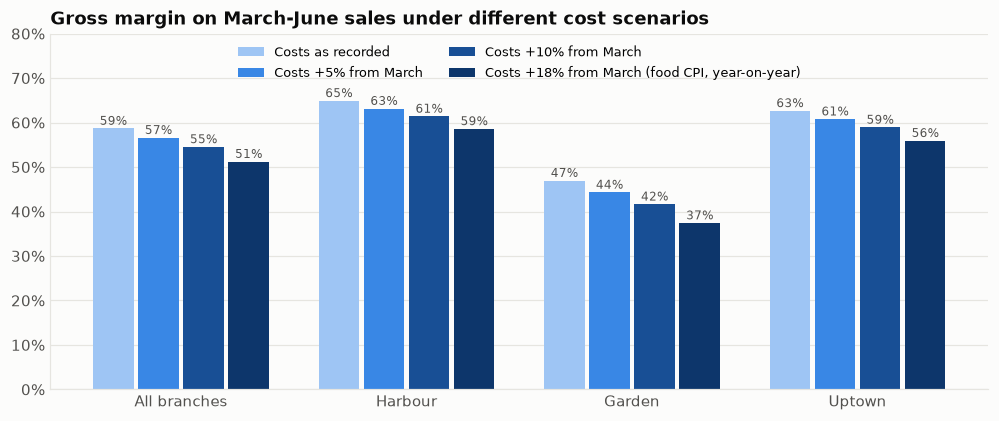

scenario,Costs as recorded,Costs +5% from March,Costs +10% from March,"Costs +18% from March (food CPI, year-on-year)"
branch,,,,
All branches,$0,"$-4,608","$-9,215","$-16,587"
Harbour,$0,"$-1,935","$-3,869","$-6,965"
Garden,$0,"$-1,921","$-3,843","$-6,917"
Uptown,$0,$-751,"$-1,503","$-2,705"


In [7]:
SCENARIOS = {"Costs as recorded": 0.0, "Costs +5% from March": 0.05, "Costs +10% from March": 0.10,
             "Costs +18% from March (food CPI, year-on-year)": 0.18}
late = df[df["Date"] >= "2026-03-01"]
rows = []
for name, bump in SCENARIOS.items():
    for b in ["All branches", *BRANCHES]:
        g = late if b == "All branches" else late[late["Branch"] == b]
        rev = g[R].sum()
        cost = g["cost_value"].sum() * (1 + bump)
        # Price rise that keeps gross profit in dollars unchanged (same quantities): extra cost / revenue
        rows.append({"scenario": name, "branch": b, "gross_profit": rev - cost, "gross_margin": 1 - cost / rev,
                     "price rise to keep gross profit in dollars": bump * g["cost_value"].sum() / rev})
scen = pd.DataFrame(rows)
base_gp = scen[scen["scenario"] == "Costs as recorded"].set_index("branch")["gross_profit"]
scen["gross profit lost vs recorded"] = scen.apply(lambda r: r["gross_profit"] - base_gp[r["branch"]], axis=1)

fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(BRANCHES) + 1)
w = 0.2
for i, (name, c) in enumerate(zip(SCENARIOS, SEQ_SCEN)):
    vals = scen[scen["scenario"] == name].set_index("branch").loc[["All branches", *BRANCHES], "gross_margin"].values
    ax.bar(x + (i - 1.5) * w, vals, width=w - 0.02, color=c, label=name)
    for xi, v in zip(x + (i - 1.5) * w, vals):
        ax.text(xi, v + 0.008, f"{v:.0%}", ha="center", color=INK2, fontsize=8)
ax.set_xticks(x, ["All branches", *BRANCHES])
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.8)
ax.set_title("Gross margin on March-June sales under different cost scenarios")
ax.legend(loc="upper center", ncols=2, fontsize=8.5)
ax.grid(axis="x", visible=False)
plt.show()

scen.pivot(index="branch", columns="scenario", values="gross profit lost vs recorded").loc[
    ["All branches", *BRANCHES], list(SCENARIOS)].style.format("${:,.0f}").set_caption(
    "Gross profit lost on March-June sales vs the recorded costs")

In [8]:
scen.pivot(index="branch", columns="scenario", values="price rise to keep gross profit in dollars").loc[
    ["All branches", *BRANCHES], list(SCENARIOS)[1:]].style.format("{:+.1%}").set_caption(
    "Menu price increase needed to keep the same gross profit in dollars (same quantities sold)")

scenario,Costs +5% from March,Costs +10% from March,"Costs +18% from March (food CPI, year-on-year)"
branch,,,
All branches,+2.1%,+4.1%,+7.4%
Harbour,+1.8%,+3.5%,+6.3%
Garden,+2.7%,+5.3%,+9.5%
Uptown,+1.9%,+3.7%,+6.7%


**Takeaway**
- If ingredient costs really rose **10% from March**, the March-June gross profit would be about **$9k lower** than recorded across the three branches, and the margin would fall by about 4 points. At **+18%** (the food CPI's year-on-year rise), it would be about **$17k lower**.
- **Garden is the most exposed.** Its costs are already about 43% higher than Harbour's (`01_eda`), so it would lose about as many dollars as Harbour (about $3.8k vs $3.9k at +10%) on much smaller sales.
- To keep the same gross profit in dollars, menu prices would have needed to rise by about **4% overall for a 10% cost increase** (about 3.5% at Harbour, 5.3% at Garden, 3.7% at Uptown), or about 7.5% for an 18% increase. Both are below the 9.8% general price increase. This supports the team's pitch to align prices upward, and gives a second reason for it: inflation, not just Garden's costs.

## 7. Conclusion and what it means for the planner

| Question | Answer |
|---|---|
| How did prices change in Lebanon? | CPI **+9.8% from January to June 2026**: +4.9% in March and +3.0% in April when the war began, then flat. Year-on-year inflation peaked at 20% in April. Food +18-19%, restaurants and hotels +16% year-on-year by April. The lira stayed at about 89,500/$ |
| Did the café's selling prices change? | **No.** One price per branch-product for all six months; the menu price index is exactly 1.000 every month |
| Did the café's ingredient costs change? | **No.** One unit cost per branch-product for all six months, despite reported jumps in flour, bread and fuel |
| Real prices | The menu became about **9% cheaper in real terms** by June |
| Margin risk | If real costs rose 10-18% from March, recorded March-June gross profit is overstated by about **$9-17k**, most at Garden |

**What it means**
1. **The cost field probably isn't the actual monthly cost.** It most likely holds standard recipe costs. Every profit figure in the team's work (the price-list pitch, Garden's gap, the planner's contribution) inherits that assumption. **Ask the company for actual ingredient costs by month**, or at least whether costs were updated during the war.
2. **For the profit planner:** prices and costs should be **inputs the company can update** (the README's `--price` and `--cost` options already allow this), and the demo should state that the historical cards use January-level costs.
3. **For the pitch:** the case for aligning prices upward gets stronger. Holding prices flat during a 10% rise in general prices is an unplanned real price cut of about 9%.
4. **What we don't claim:** that inflation changed demand, or how customers would react to a price increase. The data has no price changes to learn from, so that needs the controlled price test the README already proposes.

Sources: [Credit Libanais, Feb 2026 CPI](https://economics.creditlibanais.com/Article/213181), [Credit Libanais, Apr 2026 CPI](https://economics.creditlibanais.com/Article/213277), [Credit Libanais, May 2026 CPI](https://economics.creditlibanais.com/Article/213331), [BLOMINVEST, May 2026](https://blog.blominvestbank.com/lebanons-inflation-rate-increased-by-19-04-yoy-by-may-2026/), [BLOMINVEST, Jun 2026](https://blog.blominvestbank.com/lebanons-inflation-rate-increased-by-17-25-yoy-by-june-2026/), [Trading Economics, Apr 2026 release](https://tradingeconomics.com/lebanon/inflation-cpi/news/552692), [Trading Economics, USD/LBP](https://tradingeconomics.com/lebanon/currency), [L'Orient Today, Beirut supermarkets](https://today.lorientlejour.com/article/1497179/were-tired-we-just-want-peace-from-flour-to-fuel-war-pressures-beiruts-supermarkets.html), [Anera, food prices](https://www.anera.org/blog/food-prices-surge-in-lebanon-war-inflation-and-the-growing-threat-to-food-security/). Retrieved 2026-10-17.